# 03 · 教 Transformer 把数字倒着写

输入 `[1, 2, 3]`，期望输出 `[3, 2, 1]`。这件事人一眼就会，模型却得学会两步：**读懂输入的顺序，再按相反的顺序逐个写出数字。**

这个小任务把前两篇的积木全部用上，也让训练与生成的区别变得很清楚：练习时，我们把正确前缀交给模型；正式生成时，它要接着自己刚写的内容往下写。

## 准备一场倒序练习

使用 `transformer` 环境，从第一格顺序运行。数字 1–10 是内容，0 是起始符 **BOS**。每条输入长度固定为 6，生成也在六个数字后结束。

下面设置批量和训练步数；默认训练 1000 步，第一次体验可以先调小 `num_steps`。

In [ ]:
import copy
import math
import torch.nn as nn
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = 11
seq_len = 6
batch_size = 32
num_steps = 1000
print("Device:", device)

数据由代码现场生成：每一步拿到一批新的数字串，再用 `flip` 得到倒序答案。固定随机种子，方便之后改一个设置、比较两次练习的结果。

## 先把模型放到桌上

下面四组定义就是前两篇的积木。先顺序运行它们，再进入第一节准备训练数据；复习时可以折叠这些代码，直接看任务流程。

这次最值得追踪的是 `make_model → encode → decode → generator`：搭模型、读输入、处理前缀、给下一位数字打分。

### 注意力：每个位置从哪里取信息？

`w_q/w_k/w_v` 生成三种投影，`view` 与 `transpose` 拆出多个头，`softmax` 算出配比。最后两次矩阵乘法分别负责“汇总 V”和“融合各头”。

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)
        Q = self.w_q(q).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        K = self.w_k(k).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        V = self.w_v(v).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_head)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        attn = self.dropout(F.softmax(scores, dim=-1))
        context = torch.matmul(attn, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        return self.w_o(context)

### FFN 与连接层：加工一轮，再接着往下传

FFN 在每个位置加工特征；残差把加工结果加回输入；LayerNorm 调整一行特征的尺度。下面沿用先相加、后归一化的 Post-LN 顺序。

In [ ]:
class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w_1 = nn.Linear(d_model, d_ff)
        self.w_2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.w_2(self.dropout(F.relu(self.w_1(x))))


class LayerNorm(nn.Module):
    def __init__(self, features, eps=1e-6):
        super().__init__()
        self.a_2 = nn.Parameter(torch.ones(features))
        self.b_2 = nn.Parameter(torch.zeros(features))
        self.eps = eps
    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        variance = x.var(-1, keepdim=True, unbiased=False)
        return self.a_2 * (x - mean) / torch.sqrt(variance + self.eps) + self.b_2


class SublayerConnection(nn.Module):
    def __init__(self, size, dropout):
        super().__init__()
        self.norm = LayerNorm(size)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, sublayer):
        return self.norm(x + self.dropout(sublayer(x)))

### 输入和出口：数字查表，隐藏向量回到词表

Embedding 把数字编号变成向量，位置编码告诉模型它排第几位。Generator 则把隐藏向量映射回 11 个 token 的分数，再输出对数概率。

从“编号”进来，绕过一圈神经网络，又回到“下一个编号”的概率分布。

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=5000):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * -(math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)
        self.pe: torch.Tensor
    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)


class Embeddings(nn.Module):
    def __init__(self, d_model, vocab):
        super().__init__()
        self.lut = nn.Embedding(vocab, d_model)
        self.d_model = d_model
    def forward(self, x):
        return self.lut(x) * math.sqrt(self.d_model)


class Generator(nn.Module):
    def __init__(self, d_model, vocab):
        super().__init__()
        self.proj = nn.Linear(d_model, vocab)
    def forward(self, x):
        return F.log_softmax(self.proj(x), dim=-1)

### 把各层装成完整模型

Encoder 把源数字串写成 memory；Decoder 读取目标前缀，并查询这份 memory。`make_model` 负责建好各层、初始化参数。

每次调用 `model(src, tgt, ...)` 得到的是 Decoder 隐藏状态，后面再接 `model.generator(...)` 得到词表预测。

In [ ]:
def clones(module, N):
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])


class EncoderLayer(nn.Module):
    def __init__(self, size, self_attn, feed_forward, dropout):
        super().__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 2)
        self.size = size
    def forward(self, x, mask):
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask))
        return self.sublayer[1](x, self.feed_forward)


class Encoder(nn.Module):
    def __init__(self, layer, N):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = LayerNorm(layer.size)
    def forward(self, x, mask):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)


class DecoderLayer(nn.Module):
    def __init__(self, size, self_attn, src_attn, feed_forward, dropout):
        super().__init__()
        self.size = size
        self.self_attn = self_attn
        self.src_attn = src_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 3)
    def forward(self, x, memory, src_mask, tgt_mask):
        m = memory
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, tgt_mask))
        x = self.sublayer[1](x, lambda x: self.src_attn(x, m, m, src_mask))
        return self.sublayer[2](x, self.feed_forward)


class Decoder(nn.Module):
    def __init__(self, layer, N):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = LayerNorm(layer.size)
    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)


class Transformer(nn.Module):
    def __init__(self, encoder, decoder, src_embed, tgt_embed, generator):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_embed = src_embed
        self.tgt_embed = tgt_embed
        self.generator = generator

    def forward(self, src, tgt, src_mask, tgt_mask):
        memory = self.encode(src, src_mask)
        output = self.decode(memory, src_mask, tgt, tgt_mask)
        return output

    def encode(self, src, src_mask):
        return self.encoder(self.src_embed(src), src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        return self.decoder(self.tgt_embed(tgt), memory, src_mask, tgt_mask)


def make_model(src_vocab, tgt_vocab, N=6, d_model=512, d_ff=2048, h=8, dropout=0.1):
    c = copy.deepcopy
    attn = MultiHeadAttention(d_model, h)
    ff = PositionWiseFeedForward(d_model, d_ff, dropout)
    position = PositionalEncoding(d_model, dropout)
    model = Transformer(
        Encoder(EncoderLayer(d_model, c(attn), c(ff), dropout), N),
        Decoder(DecoderLayer(d_model, c(attn), c(attn), c(ff), dropout), N),
        nn.Sequential(Embeddings(d_model, src_vocab), c(position)),
        nn.Sequential(Embeddings(d_model, tgt_vocab), c(position)),
        Generator(d_model, tgt_vocab)
    )
    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

### 先看这两条写作路线

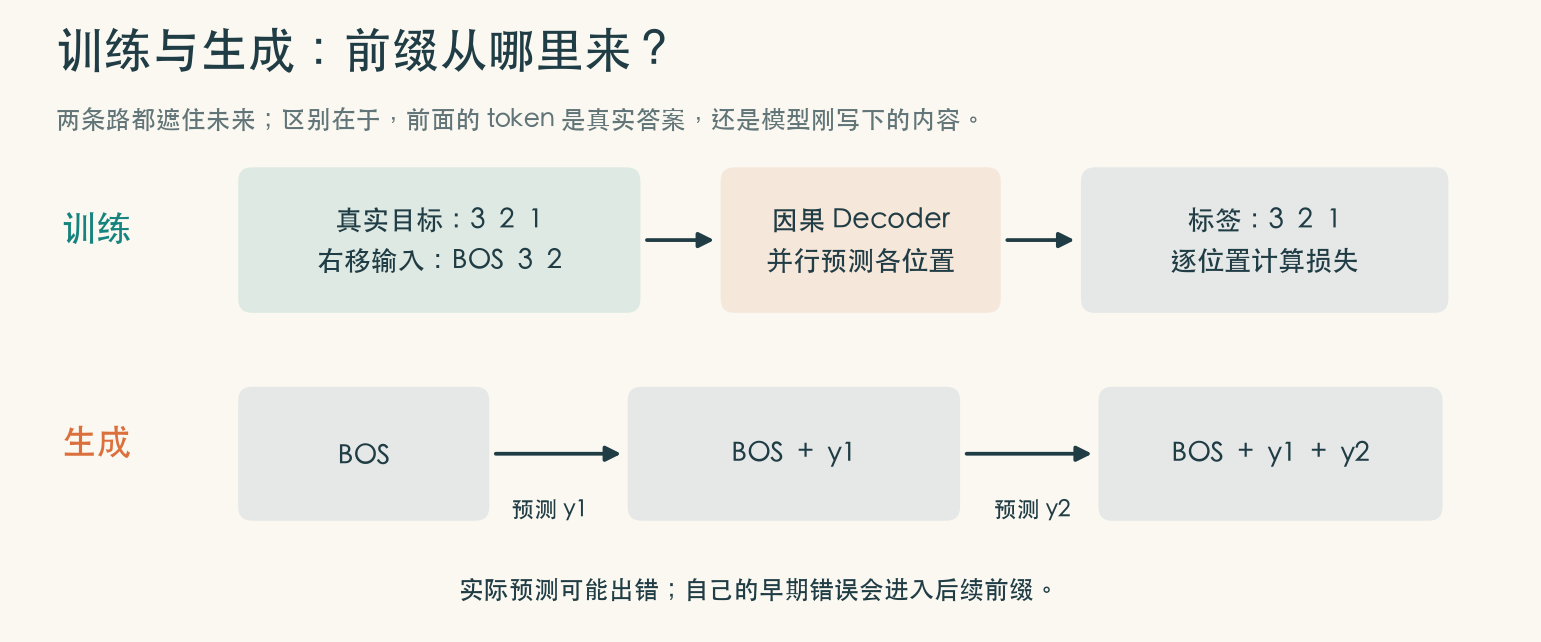

上面一条路，正确前缀由训练数据提供；下面一条路，y1、y2 是模型刚刚写出的预测。相同的 Decoder，在两种情况下收到的前缀来源不同。

## 1. Teacher forcing：把答案往右挪一格

以 `[1, 2, 3] → [3, 2, 1]` 为例，准备两行：

```text
Decoder 输入： BOS   3   2
要预测的标签：   3   2   1
```

第一位看见 BOS，要预测 3；第二位看见 BOS、3，要预测 2；第三位看见 BOS、3、2，要预测 1。

**把真实答案的前缀喂给模型，叫 teacher forcing。** 右移安排好预测关系，因果 mask 控制各位置读到的前缀。下一格会打印一条实际生成的六位样本，按相同方式上下对齐着读。

In [ ]:
def generate_batch():
    src = torch.randint(1, vocab_size, (batch_size, seq_len), device=device)
    labels = src.flip(dims=[1])
    bos = torch.zeros(batch_size, 1, dtype=torch.long, device=device)
    decoder_input = torch.cat([bos, labels[:, :-1]], dim=1)
    return src, decoder_input, labels

def make_masks(src, tgt):
    src_mask = torch.ones(src.size(0), 1, 1, src.size(1), dtype=torch.bool, device=device)
    tgt_mask = torch.ones(tgt.size(1), tgt.size(1), dtype=torch.bool, device=device).tril()
    return src_mask, tgt_mask[None, None]

src, decoder_input, labels = generate_batch()
print("Source:", src[0].cpu().tolist())
print("Decoder input:", decoder_input[0].cpu().tolist())
print("Labels:", labels[0].cpu().tolist())

检查打印的三行：`Labels` 是 `Source` 的反转；`Decoder input` 以 0 开头，后面接着标签的前五位。每个输入位置刚好对应一个“下一位数字”的问题。

## 2. 训练：让正确数字拿到更高概率

Generator 给出每个位置的对数概率。`nll_loss` 取出正确数字那一项，加上负号再求平均：

$$L=-\operatorname{mean}\bigl(\log p(\text{正确数字})\bigr).$$

正确数字的概率越高，损失越小。例如概率从 0.1 提高到 0.8，负对数损失会从约 2.30 降到 0.22。

代码先把 `(B,L,V)` 展平成 `(B*L,V)`，相当于把整个 batch 的所有位置排成一长列，然后重复：**预测 → 算误差 → 清梯度 → 反向传播 → 更新参数**。

In [ ]:
model = make_model(vocab_size, vocab_size, N=2, d_model=64, d_ff=256, h=2, dropout=0.1).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_history = []
model.train()

for step in range(num_steps):
    src, decoder_input, labels = generate_batch()
    src_mask, tgt_mask = make_masks(src, decoder_input)
    hidden = model(src, decoder_input, src_mask, tgt_mask)
    log_probs = model.generator(hidden)
    loss = F.nll_loss(log_probs.reshape(-1, vocab_size), labels.reshape(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (step + 1) % 100 == 0:
        print(f"Step {step + 1}/{num_steps}, recent loss={sum(loss_history[-100:]) / 100:.4f}")

日志每 100 步打印一次近期平均损失。它在回答：给定正确前缀时，模型给正确下一位分了多少概率？稍后的生成环节，再让模型用自己的前缀完成整串倒写。

## 3. 看看模型怎样越练越熟

每一步换一批数字，难度会有波动，所以曲线也会起伏。先看整体是在下降、变平，还是持续剧烈跳动，再找变化发生的大致位置。

这条曲线记录的，就是刚才每次练习收到的反馈。

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(loss_history)
plt.xlabel("Update step")
plt.ylabel("Negative log likelihood")
plt.title("Reverse-sequence training")
plt.tight_layout()
plt.show()

曲线告诉我们训练中的配分情况；下一格直接展示模型写出的数字。把这两份信息放在一起，能更容易分清“还没学会规律”与“生成到某一步开始跑偏”。

## 4. 自回归：接着自己刚写的内容往下写

现在把练习时的正确前缀拿开，从 BOS 开始：

```text
BOS → 预测第一位
BOS + 第一位预测 → 预测第二位
BOS + 前两位预测 → 预测第三位
……直到写满六位
```

每轮取最后一个位置上概率最高的 token，这叫**贪心解码**。新的 token 追加到前缀后，成为下一轮的输入。

Encoder 对原输入的阅读结果保持不变，因此 memory 在循环前计算一次；Decoder 随着前缀增长逐轮计算。

In [ ]:
def greedy_decode(src):
    model.eval()
    tokens = torch.zeros(src.size(0), 1, dtype=torch.long, device=device)
    with torch.no_grad():
        src_mask, _ = make_masks(src, tokens)
        memory = model.encode(src, src_mask)
        for _ in range(src.size(1)):
            _, tgt_mask = make_masks(src, tokens)
            hidden = model.decode(memory, src_mask, tokens, tgt_mask)
            next_token = model.generator(hidden[:, -1]).argmax(dim=-1, keepdim=True)
            tokens = torch.cat([tokens, next_token], dim=1)
    return tokens[:, 1:]

prompt = torch.tensor([[1, 2, 3, 4, 5, 6]], dtype=torch.long, device=device)
generated = greedy_decode(prompt)
print("Input:", prompt[0].cpu().tolist())
print("Generated:", generated[0].cpu().tolist())
print("Desired reversal:", prompt.flip(dims=[1])[0].cpu().tolist())

把 `Generated` 与 `Desired reversal` 从左到右比较。若出现差异，先找第一处：从这一处往后，模型读到的前缀就包含了自己的选择，这能帮助解释后续数字为什么一起变化。

## 从小任务里带走什么？

这次完整走过了两条路：训练时用正确前缀并行练习各位置；生成时用自己的预测逐步延长前缀。

<details>
<summary>训练时为什么能一次算所有位置？</summary>

真实目标已知，右移后的输入可以一次准备好。因果 mask 为每个位置划出自己的可见前缀，所以多处预测能并行计算。

</details>

<details>
<summary>生成为什么一位一位循环？</summary>

下一轮输入包含这一轮刚预测的 token，要等它产生后才能继续。

</details>

<details>
<summary>为什么这里使用 nll_loss？</summary>

Generator 已经做了 log_softmax。nll_loss 直接抽取标签对应的负对数概率，正好与输出配套。

</details>

想接着探索，可以给输入换一串数字，或改训练步数观察第一处错误怎样变化。下一站是[德英翻译](04_德英翻译实战.ipynb)：保留同样的训练与生成流程，再加上分词、词表和变长句子。

更远的路标：Encoder-only 模型侧重双向表示，Decoder-only 模型侧重自回归生成；KV cache 缓存前缀的键值，FlashAttention 优化注意力的显存读写。